# 01 - Data Exploration: Healthcare Facilities in Sierra Leone
**Course:** Data Science Fundamentals (FDS)  
**Topic:** Distribution and Operational Status of Healthcare Facilities Across Districts in Sierra Leone (SDG 3: Good Health and Well-being)  
**Dataset:** `data/sle_hltfac_grid3_v01.csv`

---
### Step 1: Import Libraries and Load the Dataset
**What this code does:**  
We import `pandas` (for working with data tables) and `matplotlib.pyplot` (for creating charts). We also create the `outputs/` folder if it does not already exist, and load our raw CSV file from `data/sle_hltfac_grid3_v01.csv` into a DataFrame called `df`. We do not modify or overwrite the original file.

**What the result means:**  
Confirming that the file loads without errors shows that Python can read our Sierra Leone healthcare facilities dataset properly.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Make sure the outputs folder exists for saving charts
os.makedirs("outputs", exist_ok=True)

# Load the original dataset (we never overwrite this file)
df = pd.read_csv("data/sle_hltfac_grid3_v01.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


### Step 2: Check Dataset Shape, Column Names, and Data Types
**What this code does:**  
We check `df.shape` to see how many rows and columns are in the dataset, `df.columns.tolist()` to list all column names, and `df.dtypes` to see the data type of each column (for example, whole numbers `int64`, decimals `float64`, or text `str`/`object`).

**What the result means:**  
- **Shape `(1616, 15)`** means there are **1,616 rows** (healthcare facility records) and **15 columns** (attributes about each facility).  
- Most text columns (`district`, `community`, `facility`, `type`, `ownership`, `functional`) are stored as text strings, while `lat` and `long` are decimal numbers (`float64`).  
- Notice our first data-quality problem: `geo_date` (the year the GPS location was recorded) is stored as a decimal number (`float64`, e.g., `2016.0`) instead of a whole-number year (`int64`) because it contains missing values.

In [2]:
# Show the number of rows and columns
print("Dataset Shape (rows, columns):", df.shape)

# Show the list of column names
print("\nColumn Names:")
print(df.columns.tolist())

# Show the data type of each column
print("\nData Types:")
print(df.dtypes)

Dataset Shape (rows, columns): (1616, 15)

Column Names:
['OID_', 'district', 'community', 'facility', 'fac_name', 'type', 'ownership', 'functional', 'lat', 'long', 'source', 'source_geo', 'dhis2_id', 'geo_date', 'comments']

Data Types:
OID_            int64
district          str
community         str
facility          str
fac_name          str
type              str
ownership         str
functional        str
lat           float64
long          float64
source            str
source_geo        str
dhis2_id          str
geo_date      float64
comments          str
dtype: object


### Step 3: View the First 5 Rows (`head`) and Last 5 Rows (`tail`)
**What this code does:**  
We use `df.head()` to inspect the first 5 rows of the table and `df.tail()` to inspect the last 5 rows of the table.

**What the result means:**  
Looking at the top and bottom rows helps us verify that the columns aligned properly when loading the CSV. We can see facilities from `Bo` district at the start and `Bombali` district at the end, and we can already see `NaN` (missing values) in the `comments` column and decimal `.0` values in `geo_date`.

In [3]:
# Display the first 5 rows
print("--- FIRST 5 ROWS (HEAD) ---")
display_head = df.head()
print(display_head.to_string())

print("\n--- LAST 5 ROWS (TAIL) ---")
display_tail = df.tail()
display_head

--- FIRST 5 ROWS (HEAD) ---
   OID_ district    community          facility     fac_name  type   ownership  functional       lat       long source source_geo     dhis2_id  geo_date comments
0     1       Bo     Bum Kaku     Bum Kaku MCHP     Bum Kaku  MCHP  Government  Functional  7.505273 -11.877486   DPPI        GPS  fg1YbsySsK4    2016.0      NaN
1     2       Bo        Kasse        Kasse MCHP        Kasse  MCHP  Government  Functional  7.536850 -11.919780   DPPI        GPS  d2vcCqeRJJy    2016.0      NaN
2     3       Bo  Mano Yorgbo  Mano Yorgbo MCHP  Mano Yorgbo  MCHP  Government  Functional  7.558374 -11.869090   DPPI        GPS  shJl21cKmEL    2016.0      NaN
3     4       Bo       Momajo        Momajo CHP       Momajo   CHP  Government  Functional  7.575193 -11.938020   DPPI        GPS  fRJTlzAV68y    2016.0      NaN
4     5       Bo        Jimmi         Jimmi CHC        Jimmi   CHC  Government  Functional  7.606090 -11.815840   DPPI        GPS  psVBVk4IYKD    2016.0      NaN


,OID_,district,community,facility,fac_name,type,ownership,functional,lat,long,source,source_geo,dhis2_id,geo_date,comments
0,1,Bo,Bum Kaku,Bum Kaku MCHP,Bum Kaku,MCHP,Government,Functional,7.505273,-11.877486,DPPI,GPS,fg1YbsySsK4,2016.0,NaN
1,2,Bo,Kasse,Kasse MCHP,Kasse,MCHP,Government,Functional,7.536850,-11.919780,DPPI,GPS,d2vcCqeRJJy,2016.0,NaN
2,3,Bo,Mano Yorgbo,Mano Yorgbo MCHP,Mano Yorgbo,MCHP,Government,Functional,7.558374,-11.869090,DPPI,GPS,shJl21cKmEL,2016.0,NaN
3,4,Bo,Momajo,Momajo CHP,Momajo,CHP,Government,Functional,7.575193,-11.938020,DPPI,GPS,fRJTlzAV68y,2016.0,NaN
4,5,Bo,Jimmi,Jimmi CHC,Jimmi,CHC,Government,Functional,7.606090,-11.815840,DPPI,GPS,psVBVk4IYKD,2016.0,NaN


### Step 4: View the Last 5 Rows (`tail`) Table
**What this code does:**  
We display `df.tail()` as a formatted table so we can clearly inspect the final 5 records of the dataset.

**What the result means:**  
The dataset ends at `OID_` 1616 in `Bombali` district. Even at the bottom of the file, the `comments` column is mostly `NaN` (empty).

In [4]:
# Display the last 5 rows as a table
df.tail()

,OID_,district,community,facility,fac_name,type,ownership,functional,lat,long,source,source_geo,dhis2_id,geo_date,comments
1611,1612,Bombali,Mabanta Road,Modern Clinic,Modern,CLINIC,Private,Functional,8.888148,-12.045392,DPPI,Digitized,No Data,2021.0,Requires Validation/Ground truthing
1612,1613,Tonkolili,Ninkikoro,Ninkikoro MCHP,Ninkikoro,MCHP,Government,Functional,8.991273,-11.639375,DPPI,GPS,kSlAzC2rmUu,2016.0,NaN
1613,1614,Western Area Rural,Camp Junction,Rick-Fresh Clinic,Rick-Fresh,CLINIC,Private,Functional,NaN,NaN,DPPI,NaN,No Data,NaN,no lat/long
1614,1615,Western Area Rural,Waterloo,Waterloo CEmONC- Hospital,Waterloo CEmONC-,HOSPITAL,Government,Functional,8.335116,-13.073789,DPPI,NaN,No Data,2023.0,no lat/long
1615,1616,Western Area Urban,Bathurst Street,Dr. J. Russels Clinic,Dr. J. Russels,CLINIC,Private,Functional,8.486620,-13.238572,DPPI,GPS,mKtst3QV7yE,2023.0,NaN


### Step 5: Summary Statistics for Numerical and Categorical Columns
**What this code does:**  
We call `df.describe()` to get summary statistics (count, mean, standard deviation, min, 25%, 50% median, 75%, and max) for numerical columns (`OID_`, `lat`, `long`, `geo_date`), and `df.describe(include=['object', 'str'])` to summarize text columns (count, number of unique values, most frequent value `top`, and its frequency `freq`).

**What the result means:**  
- **Latitude (`lat`)** ranges from `6.97` to `9.98` and **Longitude (`long`)** ranges from `-13.29` to `-10.31`, which matches the real geographic location of Sierra Leone in West Africa.  
- **`geo_date`** ranges from `2015` to `2023`, with a median (`50%`) of `2016`.  
- Notice that `lat`, `long`, and `geo_date` only have a count of `1561` instead of `1616`, meaning **55 facilities are missing their coordinates and year**.  
- Among categorical columns, `Government` is the most common ownership (`1,377` facilities), `MCHP` (Maternal and Child Health Post) is the most common facility type (`615` facilities), and `Functional` is the most common status (`1,596` facilities).

In [5]:
# Summary statistics for numeric columns
print("--- NUMERICAL SUMMARY STATISTICS ---")
print(df.describe())

# Summary statistics for text/categorical columns
print("\n--- CATEGORICAL SUMMARY STATISTICS ---")
df.describe(include=["object", "str"])

--- NUMERICAL SUMMARY STATISTICS ---
              OID_          lat         long     geo_date
count  1616.000000  1561.000000  1561.000000  1561.000000
mean    808.500000     8.382754   -12.006918  2017.445227
std     466.643333     0.598323     0.788847     2.338031
min       1.000000     6.967920   -13.292070  2015.000000
25%     404.750000     7.949072   -12.677411  2016.000000
50%     808.500000     8.430763   -11.983220  2016.000000
75%    1212.250000     8.777477   -11.407732  2021.000000
max    1616.000000     9.977068   -10.307440  2023.000000

--- CATEGORICAL SUMMARY STATISTICS ---


,district,community,facility,fac_name,type,ownership,functional,source,source_geo,dhis2_id,comments
count,1616,1616,1616,1616,1616,1616,1616,1616,1560,1616,93
unique,16,1398,1546,1476,5,4,2,5,3,1490,2
top,Bo,Kingharman Road,Marie Stopes Clinic,Kpetema,MCHP,Government,Functional,DPPI,GPS,No Data,no lat/long
freq,163,7,5,7,615,1377,1595,1392,1474,120,63


### Step 6: Count Missing Values per Column
**What this code does:**  
We use `df.isnull().sum()` to count how many missing (`NaN`) cells exist in each column, and we also calculate the percentage of missing values per column.

**What the result means:**  
We found missing values in **5 columns**:
1. `comments`: **1,523 missing values** (94.25% of the entire column is empty!).  
2. `source_geo`: **56 missing values** (3.47% missing).  
3. `lat`: **55 missing values** (3.40% missing).  
4. `long`: **55 missing values** (3.40% missing).  
5. `geo_date`: **55 missing values** (3.40% missing).

In [6]:
# Count missing values and calculate percentage missing per column
missing_count = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent (%)": missing_percent
})
print(missing_summary)
missing_summary[missing_summary["Missing_Count"] > 0]

            Missing_Count  Missing_Percent (%)
OID_                    0                 0.00
district                0                 0.00
community               0                 0.00
facility                0                 0.00
fac_name                0                 0.00
type                    0                 0.00
ownership               0                 0.00
functional              0                 0.00
lat                    55                 3.40
long                   55                 3.40
source                  0                 0.00
source_geo             56                 3.47
dhis2_id                0                 0.00
geo_date               55                 3.40
comments             1523                94.25


,Missing_Count,Missing_Percent (%)
lat,55,3.40
long,55,3.40
source_geo,56,3.47
geo_date,55,3.40
comments,1523,94.25


### Step 7: Count Duplicate Rows
**What this code does:**  
We check for duplicates in three ways:
1. `df.duplicated().sum()` checks if any complete rows (including the row ID `OID_`) are identical.  
2. `df.drop(columns=['OID_']).duplicated().sum()` checks if any rows are identical across all data columns when we ignore the unique row counter `OID_`.  
3. `df.duplicated(subset=['district', 'community', 'facility']).sum()` checks if the exact same facility name in the same community and district was entered more than once.

**What the result means:**  
- Full-row duplicates including `OID_` is `0` only because `OID_` counts from 1 to 1,616.  
- When we ignore `OID_`, there is **1 exact duplicate row**, and when we check by `['district', 'community', 'facility']`, there are **6 duplicate facility records** that represent the same health facility entered twice!

In [7]:
# 1. Exact duplicate rows across all columns (including OID_)
exact_dupes_all = df.duplicated().sum()

# 2. Exact duplicate rows ignoring the OID_ counter column
exact_dupes_no_id = df.drop(columns=["OID_"]).duplicated().sum()

# 3. Duplicate facilities in the same district and community
facility_dupes = df.duplicated(subset=["district", "community", "facility"]).sum()

print(f"Exact duplicates (including OID_): {exact_dupes_all}")
print(f"Exact duplicates (ignoring OID_):  {exact_dupes_no_id}")
print(f"Duplicate facility records (same district + community + facility): {facility_dupes}")

# Display the duplicate rows so we can see them
df[df.duplicated(subset=["district", "community", "facility"], keep=False)].sort_values(by=["district", "facility"])[
    ["OID_", "district", "community", "facility", "type", "ownership", "dhis2_id"]
]

Exact duplicates (including OID_): 0
Exact duplicates (ignoring OID_):  1
Duplicate facility records (same district + community + facility): 6


,OID_,district,community,facility,type,ownership,dhis2_id
1173,1174,Karene,Komoya,Komoya CHP,CHP,Government,u1jYcIxvOwn
1199,1200,Karene,Komoya,Komoya CHP,CHP,Government,No Data
1028,1029,Kenema,Kpandebu,Kpandebu CHC,CHC,Government,c35datPPon7
1076,1077,Kenema,Kpandebu,Kpandebu CHC,CHC,Government,VNn5UPn43M8
1006,1007,Kenema,Sembehun,Sembehun MCHP,MCHP,Government,PToNkRZvMMf
1084,1085,Kenema,Sembehun,Sembehun MCHP,MCHP,Government,d1CAFvShtKH
888,889,Kono,Seidu,Seidu MCHP,MCHP,Government,ADOmjElVEss
924,925,Kono,Seidu,Seidu MCHP,MCHP,Government,No Data
400,401,Tonkolili,Mabai,Mabai MCHP,MCHP,Government,ZDWdPjDJb2X
416,417,Tonkolili,Mabai,Mabai MCHP,MCHP,Government,BxLUEEytLN7


### Step 8: List Unique Values of Categorical Columns and Check Text Formatting
**What this code does:**  
We loop through the key categorical columns (`district`, `type`, `ownership`, `functional`, `source`, `source_geo`, `comments`) to list their unique values and counts. We also check all text columns for hidden leading or trailing spaces (like `"Serabu "` instead of `"Serabu"`).

**What the result means:**  
- **Districts:** All 16 districts of Sierra Leone are present (`Bo`, `Bombali`, `Bonthe`, `Falaba`, `Kailahun`, `Kambia`, `Karene`, `Kenema`, `Koinadugu`, `Kono`, `Moyamba`, `Port Loko`, `Pujehun`, `Tonkolili`, `Western Area Rural`, `Western Area Urban`).  
- **Inconsistent capitalization in `type`:** `'HOSPITAL'` (72 rows) and `'CLINIC'` (128 rows) are written in ALL CAPS, whereas full words in other columns (`'Government'`, `'Faith Based'`, `'Private'`, `'Functional'`) use Title Case.  
- **Trailing spaces in `community`:** There are **15 rows** in the `community` column that have extra spaces at the end of the text, which can cause grouping mistakes in pandas.

In [8]:
# List unique values for key categorical columns
categorical_cols = ["district", "type", "ownership", "functional", "source", "source_geo", "comments"]

for col in categorical_cols:
    print(f"=== Column: {col} ({df[col].nunique(dropna=True)} unique values) ===")
    print(df[col].value_counts(dropna=False))
    print()

# Check for leading/trailing whitespace in all text columns
print("=== Checking for Extra Leading/Trailing Spaces in Text Columns ===")
for col in df.select_dtypes(include=["object", "str"]).columns:
    extra_spaces = df[col].dropna().apply(lambda x: str(x) != str(x).strip()).sum()
    if extra_spaces > 0:
        print(f"Column '{col}' has {extra_spaces} values with extra leading/trailing spaces!")

=== Column: district (16 unique values) ===
district
Bo                    163
Kenema                144
Western Area Urban    140
Port Loko             117
Tonkolili             113
Moyamba               110
Kono                  108
Pujehun               104
Bombali                99
Kailahun               93
Bonthe                 92
Kambia                 77
Western Area Rural     75
Koinadugu              67
Karene                 63
Falaba                 51
Name: count, dtype: int64

=== Column: type (5 unique values) ===
type
MCHP        615
CHP         486
CHC         315
CLINIC      128
HOSPITAL     72
Name: count, dtype: int64

=== Column: ownership (4 unique values) ===
ownership
Government     1377
Private         168
Faith Based      60
NGO              11
Name: count, dtype: int64

=== Column: functional (2 unique values) ===
functional
Functional        1595
Non-Functional      21
Name: count, dtype: int64

=== Column: source (5 unique values) ===
source
DPPI    1392
FM

### Step 9: Chart 1 — Healthcare Facilities per District in Sierra Leone
**What this code does:**  
We count the number of healthcare facilities in each of Sierra Leone's 16 districts using `value_counts()`, plot a horizontal bar chart using `matplotlib`, add clear labels and a title, and save it as `outputs/chart1_facilities_by_district.png`.

**What the result means:**  
The chart shows large inequality in healthcare facility distribution across districts: **Bo** (`163`), **Kenema** (`144`), **Western Area Urban** (`140`), and **Port Loko** (`117`) have the highest total number of facilities, whereas newer or rural northern districts such as **Falaba** (`51`), **Karene** (`63`), and **Koinadugu** (`67`) have the fewest facilities.

Saved: outputs/chart1_facilities_by_district.png


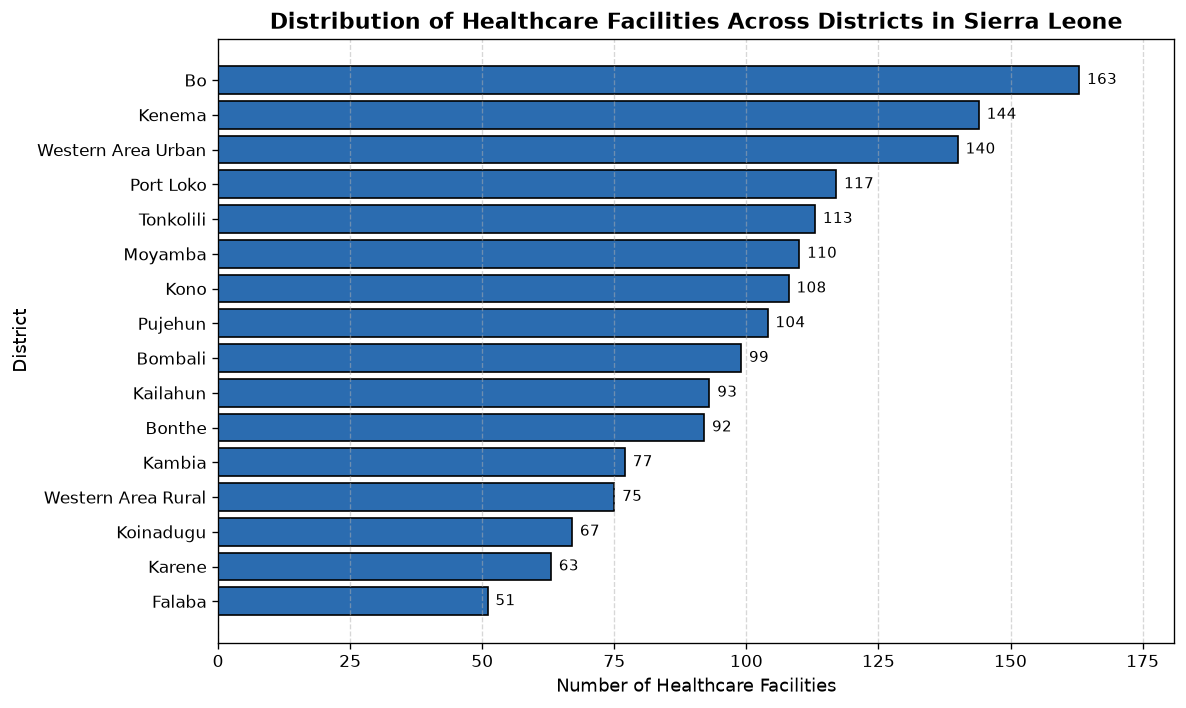

In [9]:
# Chart 1: Number of Healthcare Facilities by District
district_counts = df["district"].value_counts().sort_values(ascending=True)

plt.figure(figsize=(10, 6))
bars = plt.barh(district_counts.index, district_counts.values, color="#2b6cb0", edgecolor="black")
plt.title("Distribution of Healthcare Facilities Across Districts in Sierra Leone", fontsize=13, fontweight="bold")
plt.xlabel("Number of Healthcare Facilities", fontsize=11)
plt.ylabel("District", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Add value labels at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + 1.5, bar.get_y() + bar.get_height() / 2, f"{int(width)}", va="center", fontsize=9)

plt.xlim(0, district_counts.max() + 18)
plt.tight_layout()
plt.savefig("outputs/chart1_facilities_by_district.png", dpi=150)
plt.show()
print("Saved: outputs/chart1_facilities_by_district.png")

### Step 10: Chart 2 — Healthcare Facilities by Facility Type
**What this code does:**  
We count how many facilities belong to each facility type (`MCHP`, `CHP`, `CHC`, `CLINIC`, `HOSPITAL`), plot a vertical bar chart, and save it as `outputs/chart2_facilities_by_type.png`.

**What the result means:**  
Primary healthcare units make up the vast majority of facilities in Sierra Leone:
- **MCHP (Maternal and Child Health Post):** `615` facilities (the largest group, serving small rural communities)  
- **CHP (Community Health Post):** `486` facilities  
- **CHC (Community Health Centre):** `315` facilities  
- **CLINIC:** `128` facilities  
- **HOSPITAL:** Only `72` hospitals across the entire country, showing that advanced hospital care is relatively scarce.

Saved: outputs/chart2_facilities_by_type.png


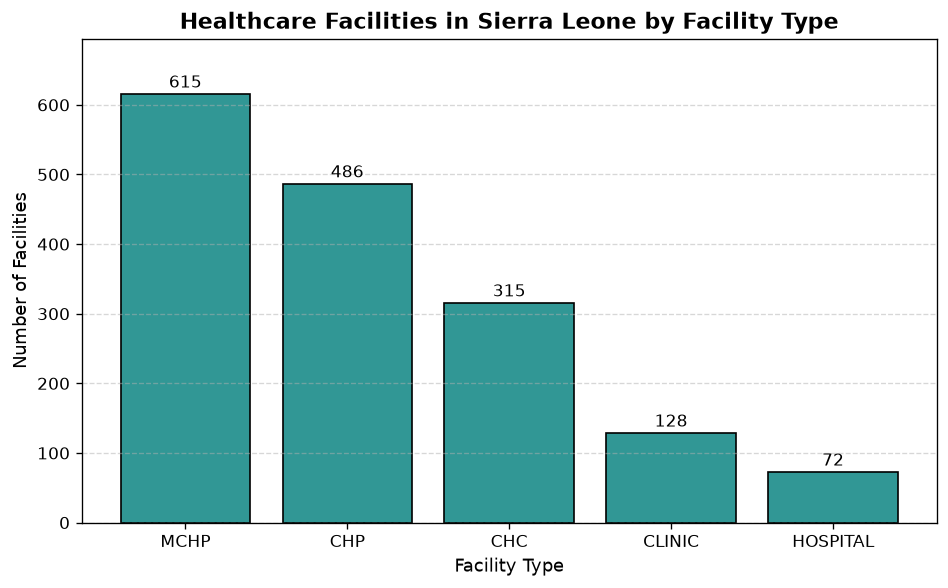

In [10]:
# Chart 2: Number of Healthcare Facilities by Facility Type
type_counts = df["type"].value_counts()

plt.figure(figsize=(8, 5))
bars = plt.bar(type_counts.index, type_counts.values, color="#319795", edgecolor="black")
plt.title("Healthcare Facilities in Sierra Leone by Facility Type", fontsize=13, fontweight="bold")
plt.xlabel("Facility Type", fontsize=11)
plt.ylabel("Number of Facilities", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 10, f"{int(height)}", ha="center", fontsize=10)

plt.ylim(0, type_counts.max() + 80)
plt.tight_layout()
plt.savefig("outputs/chart2_facilities_by_type.png", dpi=150)
plt.show()
print("Saved: outputs/chart2_facilities_by_type.png")

### Step 11: Chart 3 — Healthcare Facilities by Ownership Category
**What this code does:**  
We count how many healthcare facilities are managed by each ownership category (`Government`, `Private`, `Faith Based`, `NGO`), plot a bar chart, and save it as `outputs/chart3_facilities_by_ownership.png`.

**What the result means:**  
The chart shows that **Government** owns and operates the overwhelming majority of healthcare facilities in Sierra Leone (`1,377` out of `1,616`, or `85.2%`), followed by **Private** (`168`), **Faith Based** (`60`), and **NGO** (`11`) facilities.

Saved: outputs/chart3_facilities_by_ownership.png


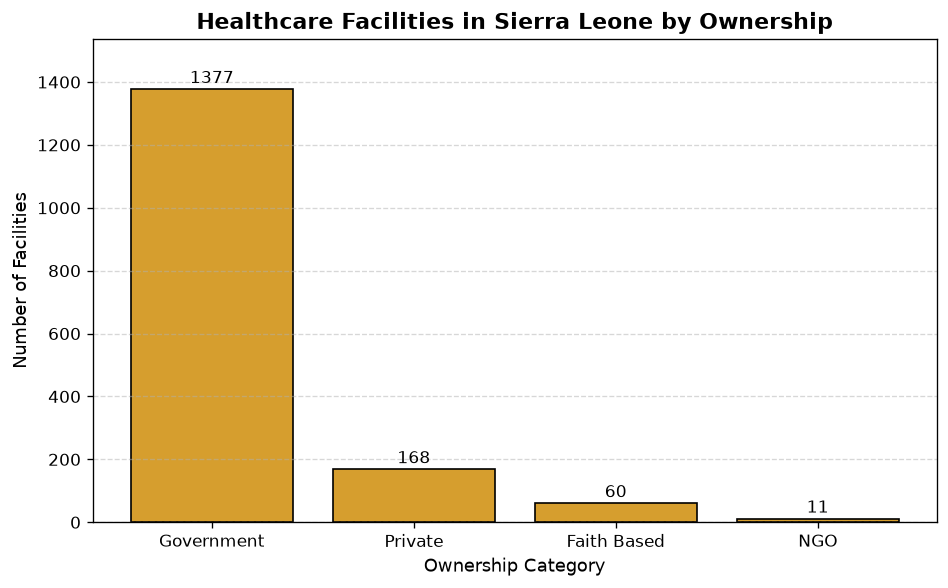

In [11]:
# Chart 3: Number of Healthcare Facilities by Ownership
ownership_counts = df["ownership"].value_counts()

plt.figure(figsize=(8, 5))
bars = plt.bar(ownership_counts.index, ownership_counts.values, color="#d69e2e", edgecolor="black")
plt.title("Healthcare Facilities in Sierra Leone by Ownership", fontsize=13, fontweight="bold")
plt.xlabel("Ownership Category", fontsize=11)
plt.ylabel("Number of Facilities", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 20, f"{int(height)}", ha="center", fontsize=10)

plt.ylim(0, ownership_counts.max() + 160)
plt.tight_layout()
plt.savefig("outputs/chart3_facilities_by_ownership.png", dpi=150)
plt.show()
print("Saved: outputs/chart3_facilities_by_ownership.png")

---
## Summary of Data-Quality Problems Found in `01_exploration.ipynb`

Based on our exploration of `data/sle_hltfac_grid3_v01.csv` (1,616 rows and 15 columns), we identified **5 main data-quality problems** that must be fixed in `02_cleaning.ipynb`:

1. **Wrong Data Type (`geo_date`):**  
   - The `geo_date` column represents the year the GPS coordinate was collected (e.g., `2016`), but pandas loaded it as a decimal number (`float64`, showing `2016.0`) because of missing values (`NaN`). It should be stored as a whole-number integer year.
2. **Missing Values (`NaN`) in 5 Columns:**  
   - `comments`: **1,523 missing values** out of 1,616 rows (**94.25% empty**), making this column almost completely unusable.  
   - `source_geo`: **56 missing values** (3.47% missing).  
   - `lat` (Latitude): **55 missing values** (3.40% missing).  
   - `long` (Longitude): **55 missing values** (3.40% missing).  
   - `geo_date`: **55 missing values** (3.40% missing).
3. **Inconsistent Text Formatting & Whitespace:**  
   - **Trailing whitespace:** `community` has **15 rows** with extra spaces at the end (such as `"Serabu "` instead of `"Serabu"`), which can cause duplicate or grouping errors.  
   - **Inconsistent capitalization in `type`:** `'HOSPITAL'` (72 rows) and `'CLINIC'` (128 rows) are written in ALL CAPS (200 rows total), while full words in other categorical columns (`'Government'`, `'Faith Based'`, `'Private'`, `'Functional'`) use Title Case.
4. **Duplicate Records:**  
   - Because `OID_` is a simple row counter (1 to 1,616), full-row duplicates appear to be 0 at first glance. However, ignoring `OID_` reveals **1 exact duplicate row**, and checking by `['district', 'community', 'facility']` reveals **6 duplicate facility entries** where the same healthcare facility in the same community and district was recorded twice.
5. **Coordinate / Numeric Outlier Verification Needed:**  
   - With 55 missing coordinates and GPS measurements from multiple sources (`DPPI`, `WHO`, `FMFL`, `SARA`, `NEMS`), we must check `lat`, `long`, and `geo_date` against both Sierra Leone's geographic bounding box (`lat` 6.9° to 10.0°, `long` -13.4° to -10.2°) and the statistical IQR (Interquartile Range) rule during cleaning.